# L35 - Spektrale Schätzverfahren (Lösung zu Aufgabe 35)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken (`l35.m`)](./l35.m).

Weitere benötigne MATLAB `*.m`-Dateien:  [`lyw.m`](./lyw.m) / [`lburg_algo.m`](./lburg_algo.m) / [`lcov.m`](./lcov.m)

In [1]:
MA = 1;
AR = [1.0000   -2.2346    2.3921   -2.0324,...
      1.2865   -0.4954    0.2322   -0.2554    0.1848];
NFFT = 2^6;
n = length(AR)-1;

N = 64;
N_vor = 2^11;
mc_run = 2e3;

## Teilaufgabe a:  Einschwingverhalten

exakte AKF (eingeschw. Zustand)

Exakten PARCOR-Koeffizienten:
0.9785
-0.9279
0.1531
-0.6974
0.1815
-0.1563
-0.1631
-0.1848



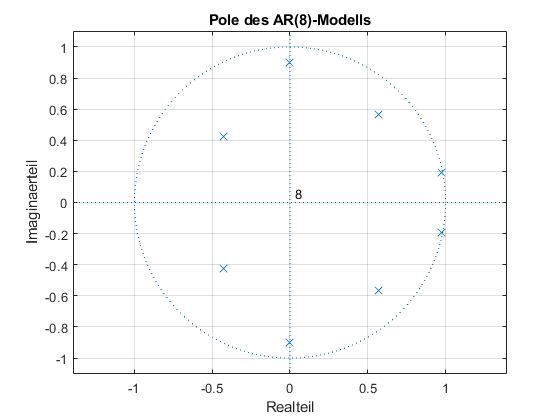

In [3]:
% # grafische Ausgabe # %
figure;
[h1,h2,h3] = zplane(MA,AR); 
set(h1,'Visible','off');
title(sprintf('Pole des AR(%d)-Modells',length(AR)-1)); 
grid;
xlabel('Realteil'); 
ylabel('Imaginaerteil');


g = zeros(length(n),1);

h_arma = impz(MA,AR);
rxx_all = xcorr(h_arma);
index = (length(rxx_all)+1)/2;
rxx = rxx_all(index:index+n);
var_i = rxx(1);
g(1) = rxx(2)/rxx(1);
var_i = [var_i (1-abs(g(1)).^2)*var_i];
ARcoeff = [1 -g(1)];


for i = 2:n
    g(i) = (ARcoeff*rxx(i+1:-1:2))./var_i(i);
    var_i = [var_i (1-abs(g(i)).^2)*var_i(i)];
    ARcoeff = [ARcoeff 0]-fliplr(conj([ARcoeff 0]))*g(i);
end

disp('Exakten PARCOR-Koeffizienten:');
fprintf('%1.4f\n',g);

##  Teilaufgabe b:  Exkates LDS

.......Bitte warten: Berechnung erfolgt.....



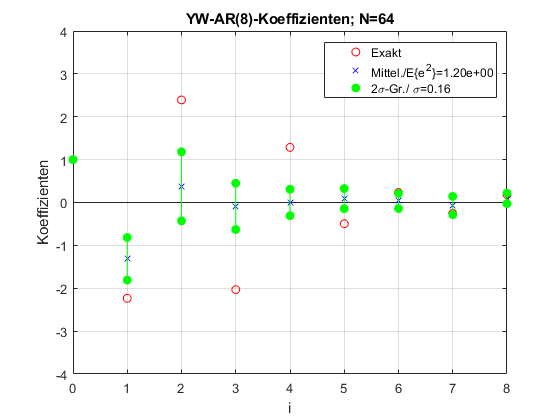

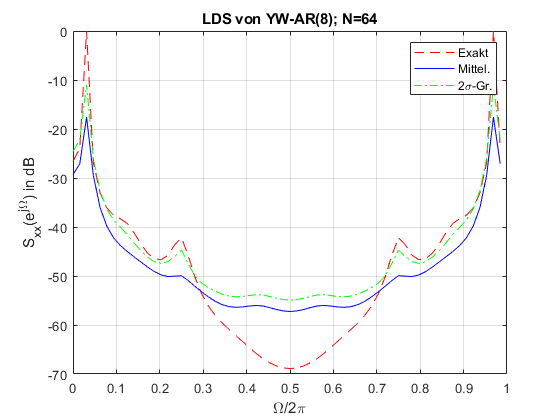

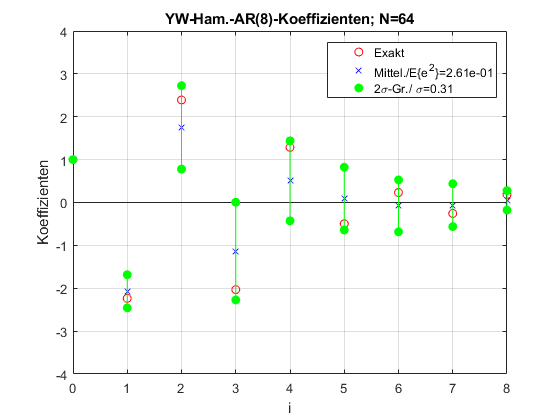

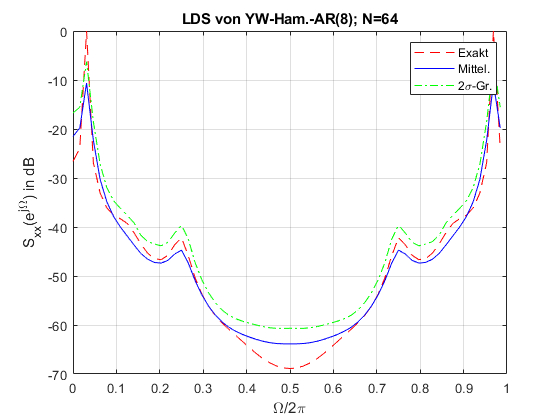

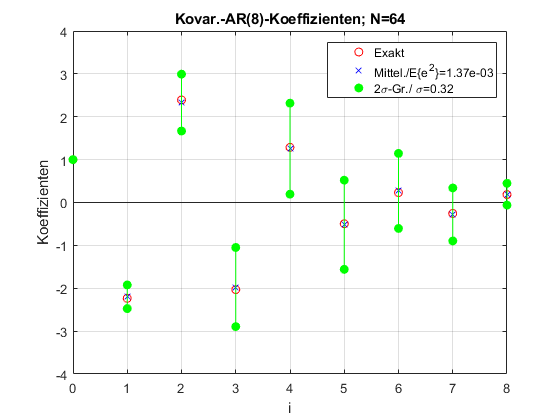

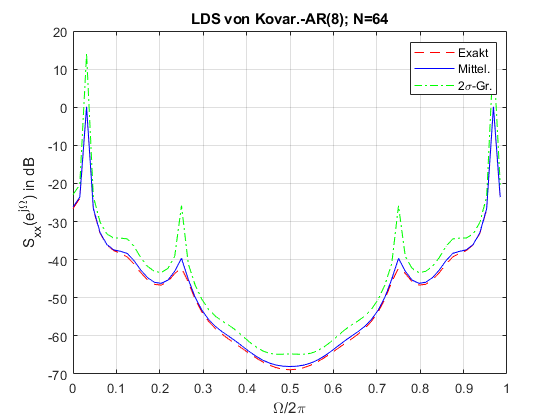

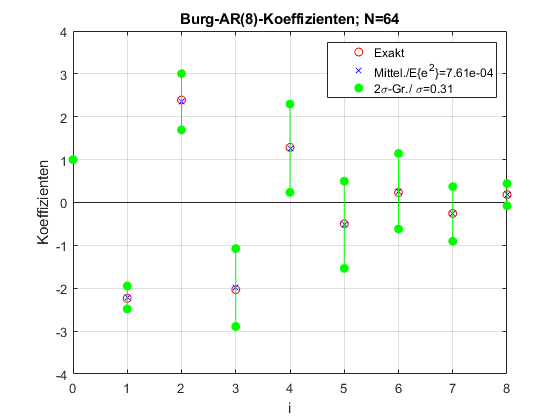

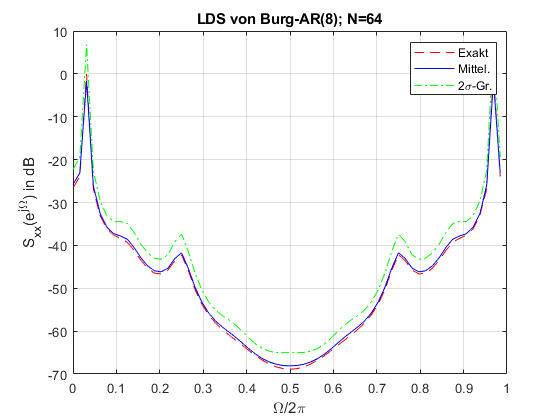

In [4]:
Omega_norm  = 0:1/NFFT:1-1/NFFT;
Sxx_ex = abs(fft(MA,NFFT)./fft(AR,NFFT)).^2;
Sxx_ar = zeros(mc_run,NFFT);
Coeff = zeros(mc_run,length(AR));

disp('.......Bitte warten: Berechnung erfolgt.....');

for run = 1:4
    for run1 = 1:mc_run
        noise = randn(1,20*N+N_vor);
        x_all = filter(MA,AR,noise);

        switch run
            case 1 
                x = x_all(N_vor+1:N_vor+1+N);
                [ARcoeff] = lyw(x,n,1); 
                str = 'YW';
            case 2 
                x = x_all(N_vor+1:N_vor+1+N);
                x_ham = x.*hamming(length(x)).';
                [ARcoeff] = lyw(x_ham,n,1); 
                str = 'YW-Ham.';
            case 3
                x = x_all(N_vor+1:N_vor+1+N);
                [ARcoeff] = lcov(x,n); 
                str = 'Kovar.';
            case 4 
                x = x_all(N_vor+1:N_vor+1+N);
                [ARcoeff] = lburg_algo(x,N,n,MA,AR); 
                str = 'Burg';
        end
        
        Coeff(run1,:) = ARcoeff;
        Sxx_ar(run1,:) = abs(ones(1,NFFT)./fft(ARcoeff,NFFT)).^2;
    end

    Coeff_mean = mean(Coeff,1);
    Coeff_std = std(Coeff,1);
    C2sig_o = Coeff_mean+2*Coeff_std;
    C2sig_u = Coeff_mean-2*Coeff_std;
    Coeff_lst = mean(abs(AR-Coeff_mean).^2);
    Sxx_mean = mean(Sxx_ar,1);
    Sxx_2sigma = Sxx_mean+2*std(Sxx_ar,1);
    
    figure;
    h1=stem(0:n,AR,'ro');  hold on;
    h2=stem(0:n,Coeff_mean,'bx');  hold on;
    h3=stem(0:n,C2sig_o,'go','filled'); hold on;
    h4=stem(0:n,C2sig_u,'go','filled');
    set(h1,'Linestyle','none');
    set(h2,'Linestyle','none');
    set(h3,'Linestyle','none');
    set(h4,'Linestyle','none')
    x_lines=[0:n; 0:n; nan*ones(1,n+1)];
    stddev_lines=[C2sig_u; C2sig_o; nan*ones(1,n+1)];
    plot(x_lines(:),stddev_lines(:),'g');
    title(sprintf('%s-AR(%d)-Koeffizienten; N=%d',str,n,N));
    xlabel('i'); ylabel('Koeffizienten'); grid; axis([0 length(AR)-1 -4 4]);
    legend([h1(1),h2(1),h3(1)],'Exakt',...
        ['Mittel./E\{e^2\}=',sprintf('%1.2e',Coeff_lst)],...
        ['2\sigma-Gr./ \sigma=',sprintf('%1.2f',mean(Coeff_std))]);
    hold off;

    % # grafische Ausgabe # %
    figure;
    h1 = plot(Omega_norm, 10*log10(Sxx_ex/max(Sxx_ex)),'r--');     hold on;
    h2 = plot(Omega_norm, 10*log10(Sxx_mean/max(Sxx_ex)),'b-');    hold on;
    h3 = plot(Omega_norm, 10*log10(Sxx_2sigma/max(Sxx_ex)),'g-.'); hold off;
    ylabel('S_{xx}(e^{j\Omega}) in dB');
    legend([h1,h2,h3],'Exakt','Mittel.','2\sigma-Gr.');
    title(sprintf('LDS von %s-AR(%d); N=%d',str,n,N));  
    xlabel('\Omega/2\pi');
    grid;
end
% #####  EOF  #####